# Otimizacao de preco com base na elasticidade-preco da demanda

## Objetivo

Um cafe vende quatro itens (hamburguer, coca, limonada e cafe), avulsos e em combos.
Cada produto vendavel tem um identificador (`SELL_ID`). Para cada `SELL_ID` queremos responder:

1. **Quanto a quantidade vendida cai quando o preco sobe?** (elasticidade-preco da demanda)
2. **Qual preco maximiza o lucro?**

## Roteiro

| Etapa | O que e feito |
|---|---|
| 1. Carregar | Ler os tres CSVs: metadados de venda, transacoes e calendario |
| 2. Preparar | Converter datas, tratar nulos, agregar por dia e juntar as tabelas |
| 3. Isolar o dia normal | Remover feriado, fim de semana e recesso escolar para medir so o efeito do preco |
| 4. Explorar | Ver a relacao preco x quantidade por `SELL_ID` |
| 5. Modelar a demanda | Regressao linear `QUANTITY ~ PRICE` por `SELL_ID`; extrair a elasticidade |
| 6. Otimizar o preco | Varrer precos, calcular o lucro previsto e escolher o de maior lucro |
| 7. Conclusao | Tabela final e limitacoes |

In [1]:
import pathlib

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="ticks")
pd.set_option("display.max_columns", None)

DATA_DIR = pathlib.Path.cwd()  # os tres CSVs estao na mesma pasta do notebook

## 1. Carregar os dados

- **Sell Meta Data** - o que compoe cada `SELL_ID`: item avulso (`SELL_CATEGORY = 0`) ou combo (`SELL_CATEGORY = 2`).
- **Transaction Store** - uma linha por dia / `SELL_ID`: preco praticado e quantidade vendida.
- **Date Info** - calendario: feriado, fim de semana, recesso escolar, temperatura.

In [2]:
def load_raw(data_dir=DATA_DIR):
    """Le os tres CSVs originais, sem transformacoes."""
    sell_meta = pd.read_csv(data_dir / "Cafe+-+Sell+Meta+Data.csv")
    transactions = pd.read_csv(data_dir / "Cafe+-+Transaction+-+Store.csv")
    date_info = pd.read_csv(data_dir / "Cafe+-+DateInfo.csv")
    return sell_meta, transactions, date_info


sell_meta, transactions, date_info = load_raw()
print(f"sell_meta {sell_meta.shape} | transactions {transactions.shape} | date_info {date_info.shape}")
sell_meta

sell_meta (11, 4) | transactions (5404, 5) | date_info (1349, 7)


,SELL_ID,SELL_CATEGORY,ITEM_ID,ITEM_NAME
0,1070,0,7821,BURGER
1,3055,0,3052,COFFEE
2,3067,0,5030,COKE
3,3028,0,6249,LEMONADE
4,2051,2,7821,BURGER
5,2051,2,5030,COKE
6,2052,2,7821,BURGER
7,2052,2,6249,LEMONADE
8,2053,2,7821,BURGER
9,2053,2,5030,COKE


Um combo (`SELL_CATEGORY = 2`) tem varias linhas em `sell_meta`, uma por item que
ele contem, mas e vendido a **um unico preco**. A unidade de analise, portanto, e o
`SELL_ID`, nao o item. A tabela abaixo resume o que cada `SELL_ID` representa e
quantas transacoes existem para ele.

In [3]:
sell_units = sell_meta.groupby("SELL_ID").agg(
    category=("SELL_CATEGORY", "first"),
    items=("ITEM_NAME", lambda s: " + ".join(sorted(s))),
)
sell_units["kind"] = np.where(sell_units["category"].eq(0), "avulso", "combo")
sell_units["n_transacoes"] = transactions["SELL_ID"].value_counts().reindex(sell_units.index).fillna(0).astype(int)
sell_units

,category,items,kind,n_transacoes
SELL_ID,,,,
1070,0,BURGER,avulso,1351
2051,2,BURGER + COKE,combo,1351
2052,2,BURGER + LEMONADE,combo,1351
2053,2,BURGER + COFFEE + COKE,combo,1351
3028,0,LEMONADE,avulso,0
3055,0,COFFEE,avulso,0
3067,0,COKE,avulso,0


As transacoes cobrem so 4 dos 7 `SELL_ID` (um burguer avulso e tres combos). Os
demais nao tem historico de vendas e ficam de fora da modelagem.

## 2. Preparar e juntar as tabelas

1. **Datas para `datetime`.** Os arquivos usam formatos diferentes (`01/01/12` nas
   transacoes, `1/1/12` no calendario). Juntar por texto casaria so parte dos dias;
   convertendo para data o casamento fica completo.
2. **`HOLIDAY` nulo** significa dia sem feriado -> preenche com `"No Holiday"`.
3. **Agregar** as transacoes por `SELL_ID`, data e preco (soma de `QUANTITY`).
4. **Juntar** com o calendario e com o rotulo de cada `SELL_ID`.

In [4]:
def build_daily_panel(transactions, date_info, sell_units):
    """Painel diario: uma linha por (SELL_ID, data, preco) com o contexto do calendario."""
    cal = date_info.copy()
    cal["CALENDAR_DATE"] = pd.to_datetime(cal["CALENDAR_DATE"], format="%m/%d/%y")
    cal["HOLIDAY"] = cal["HOLIDAY"].fillna("No Holiday")

    tx = transactions.copy()
    tx["CALENDAR_DATE"] = pd.to_datetime(tx["CALENDAR_DATE"], format="%m/%d/%y")
    daily = tx.groupby(["SELL_ID", "CALENDAR_DATE", "PRICE"], as_index=False)["QUANTITY"].sum()

    return (
        daily.merge(cal, on="CALENDAR_DATE", how="left")
        .join(sell_units[["items", "kind"]], on="SELL_ID")
    )


panel = build_daily_panel(transactions, date_info, sell_units)
print(
    f"{len(panel)} linhas | "
    f"{panel.CALENDAR_DATE.min().date()} a {panel.CALENDAR_DATE.max().date()} | "
    f"celulas nulas: {int(panel.isna().sum().sum())}"
)
panel.head()

5404 linhas | 2012-01-01 a 2015-09-10 | celulas nulas: 0


,SELL_ID,CALENDAR_DATE,PRICE,QUANTITY,YEAR,HOLIDAY,IS_WEEKEND,IS_SCHOOLBREAK,AVERAGE_TEMPERATURE,IS_OUTDOOR,items,kind
0,1070,2012-01-01,15.5,46,2012,New Year,1,0,24.8,0,BURGER,avulso
1,1070,2012-01-02,15.5,70,2012,New Year,0,0,24.8,0,BURGER,avulso
2,1070,2012-01-03,15.5,62,2012,New Year,0,0,32.0,1,BURGER,avulso
3,1070,2012-01-04,15.5,88,2012,No Holiday,0,0,32.0,1,BURGER,avulso
4,1070,2012-01-05,15.5,104,2012,No Holiday,0,0,24.8,0,BURGER,avulso


## 3. Isolar o dia normal (business as usual)

A elasticidade que interessa e a resposta ao **preco**, nao a feriados ou clima.
Feriado, fim de semana e recesso escolar tem padrao de consumo proprio e sao
removidos. Sobra o comportamento de um dia comum.

In [5]:
def business_as_usual(panel, outdoor_only=False):
    """Mantem so dias comuns: sem feriado, sem fim de semana, sem recesso escolar."""
    mask = (
        panel["HOLIDAY"].eq("No Holiday")
        & panel["IS_WEEKEND"].eq(0)
        & panel["IS_SCHOOLBREAK"].eq(0)
    )
    if outdoor_only:
        mask &= panel["IS_OUTDOOR"].eq(1)
    return panel.loc[mask].copy()


bau = business_as_usual(panel)
print(f"{len(bau)} de {len(panel)} linhas mantidas ({len(bau) / len(panel):.0%})")

2832 de 5404 linhas mantidas (52%)


## 4. Explorar preco x quantidade

Para cada `SELL_ID` a nuvem de pontos deve cair da esquerda para a direita: preco
maior, quantidade menor. A inclinacao dessa nuvem e o que o modelo vai estimar.

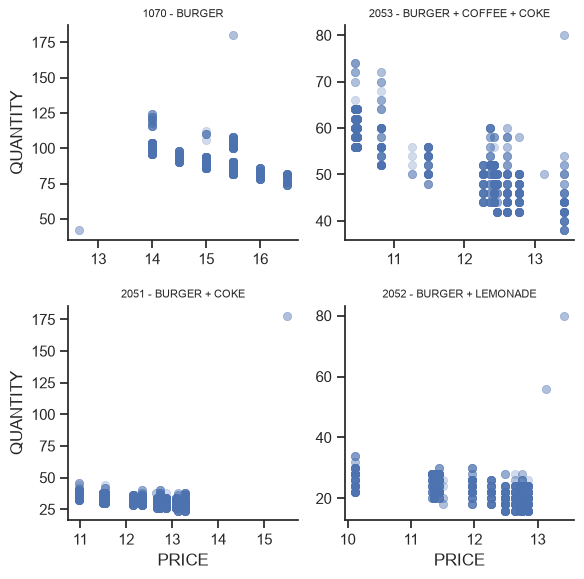

In [6]:
order = [s for s in sell_units.sort_values(["kind", "items"]).index if s in set(bau["SELL_ID"])]
g = sns.relplot(
    data=bau, x="PRICE", y="QUANTITY",
    col="SELL_ID", col_order=order, col_wrap=2,
    height=3.0, alpha=0.25, edgecolor=None,
    facet_kws={"sharex": False, "sharey": False},
)
for sid, ax in g.axes_dict.items():
    ax.set_title(f"{sid} - {sell_units.at[sid, 'items']}", fontsize=8)
plt.show()

## 5. Modelar a demanda e medir a elasticidade

Para cada `SELL_ID` ajusta-se uma regressao linear:

$$\text{QUANTITY} = \beta_0 + \beta_1 \cdot \text{PRICE} + \varepsilon$$

- $\beta_1$ (`slope`) e a variacao de unidades vendidas por real a mais no preco.
- A **elasticidade-preco** no ponto medio e $\beta_1 \cdot \bar{P} / \bar{Q}$:
  variacao percentual da quantidade para 1% de aumento no preco. Abaixo de $-1$ a
  demanda e elastica (a receita cai quando o preco sobe).
- `slope_pvalue` diz se a inclinacao e estatisticamente diferente de zero.

In [7]:
def fit_demand_model(df):
    """Regressao OLS QUANTITY ~ PRICE."""
    return smf.ols("QUANTITY ~ PRICE", data=df).fit()


def price_elasticity(model, df):
    """Elasticidade-preco da demanda avaliada no preco e na quantidade medios."""
    slope = model.params["PRICE"]
    return slope * df["PRICE"].mean() / df["QUANTITY"].mean()


def fit_all(bau, sell_units, min_obs=30):
    """Ajusta um modelo por SELL_ID e devolve (resumo, modelos, amostras)."""
    rows, models, samples = [], {}, {}
    for sell_id in sell_units.index:
        df = bau.loc[bau["SELL_ID"].eq(sell_id)]
        if len(df) < min_obs:
            continue
        model = fit_demand_model(df)
        models[sell_id], samples[sell_id] = model, df
        rows.append(
            {
                "sell_id": sell_id,
                "items": sell_units.at[sell_id, "items"],
                "kind": sell_units.at[sell_id, "kind"],
                "n": len(df),
                "slope": model.params["PRICE"],
                "slope_pvalue": model.pvalues["PRICE"],
                "r2": model.rsquared,
                "elasticity": price_elasticity(model, df),
                "avg_price": df["PRICE"].mean(),
            }
        )
    summary = pd.DataFrame(rows).set_index("sell_id").sort_values("elasticity")
    return summary, models, samples


demand_summary, models, samples = fit_all(bau, sell_units)
demand_summary.round(3)

,items,kind,n,slope,slope_pvalue,r2,elasticity,avg_price
sell_id,,,,,,,,
1070,BURGER,avulso,708,-8.051,0.000,0.285,-1.326,15.116
2053,BURGER + COFFEE + COKE,combo,708,-5.667,0.000,0.587,-1.301,11.911
2052,BURGER + LEMONADE,combo,708,-2.112,0.000,0.118,-1.112,11.972
2051,BURGER + COKE,combo,708,-0.842,0.053,0.005,-0.318,12.335


`slope` negativo com `slope_pvalue` baixo confirma que preco maior reduz a
quantidade. So esses `SELL_ID` entram na otimizacao; os demais nao tem relacao
preco-quantidade confiavel neste recorte.

## 6. Encontrar o preco de lucro maximo

Lucro previsto para um preco $p$:

$$\text{lucro}(p) = (p - \text{custo}) \times \widehat{Q}(p)$$

$\widehat{Q}(p)$ vem do modelo de demanda. O custo unitario nao esta nos dados;
seguindo a premissa do estudo original, usa-se 90% do menor preco ja praticado.
Varre-se uma grade de precos e escolhe-se o de maior lucro previsto.

In [8]:
def optimize_price(model, df, unit_cost=None, span=(0.8, 1.5), step=0.05):
    """Varre uma grade de precos e devolve o ponto de lucro maximo previsto."""
    if unit_cost is None:
        unit_cost = 0.9 * df["PRICE"].min()

    lo, hi = span[0] * df["PRICE"].min(), span[1] * df["PRICE"].max()
    grid = pd.DataFrame({"PRICE": np.arange(lo, hi, step)})
    grid["QUANTITY"] = model.predict(grid).clip(lower=0)
    grid["PROFIT"] = (grid["PRICE"] - unit_cost) * grid["QUANTITY"]

    best = grid.loc[grid["PROFIT"].idxmax()]
    current_price = df["PRICE"].mean()
    current_qty = float(model.predict(pd.DataFrame({"PRICE": [current_price]})).clip(lower=0).iloc[0])
    current_profit = (current_price - unit_cost) * current_qty
    return {
        "unit_cost": unit_cost,
        "current_price": current_price,
        "optimal_price": best["PRICE"],
        "optimal_profit": best["PROFIT"],
        "profit_uplift": best["PROFIT"] / current_profit - 1 if current_profit > 0 else np.nan,
    }, grid


elastic = demand_summary.query("slope < 0 and slope_pvalue < 0.05").index
results = pd.DataFrame.from_dict(
    {sid: optimize_price(models[sid], samples[sid])[0] for sid in elastic},
    orient="index",
).sort_values("profit_uplift", ascending=False)
results.round(2)

,unit_cost,current_price,optimal_price,optimal_profit,profit_uplift
2052,9.11,11.97,15.95,98.15,0.51
2053,9.40,11.91,15.26,192.66,0.48
1070,11.38,15.12,18.96,461.04,0.34


### Curva de lucro de um `SELL_ID`

A quantidade cai de forma linear com o preco e o lucro desenha uma parabola. O
topo da parabola e o preco recomendado.

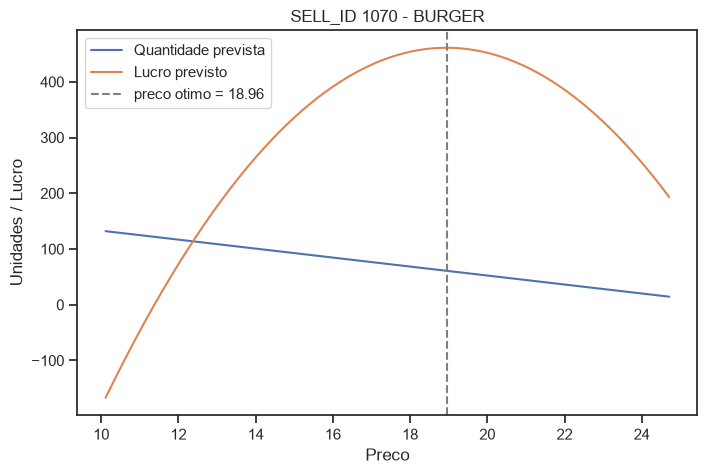

In [9]:
example = elastic[0]  # SELL_ID mais elastico
_, grid = optimize_price(models[example], samples[example])
opt = grid.loc[grid["PROFIT"].idxmax()]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(grid["PRICE"], grid["QUANTITY"], label="Quantidade prevista")
ax.plot(grid["PRICE"], grid["PROFIT"], label="Lucro previsto")
ax.axvline(opt["PRICE"], color="grey", ls="--", label=f"preco otimo = {opt['PRICE']:.2f}")
ax.set(xlabel="Preco", ylabel="Unidades / Lucro",
       title=f"SELL_ID {example} - {sell_units.at[example, 'items']}")
ax.legend()
plt.show()

In [10]:
final = (
    sell_units[["items", "kind", "n_transacoes"]]
    .join(demand_summary[["n", "elasticity", "slope_pvalue", "avg_price"]])
    .join(results[["optimal_price", "profit_uplift"]])
)
final.round(2)

,items,kind,n_transacoes,n,elasticity,slope_pvalue,avg_price,optimal_price,profit_uplift
SELL_ID,,,,,,,,,
1070,BURGER,avulso,1351,708.0,-1.33,0.00,15.12,18.96,0.34
2051,BURGER + COKE,combo,1351,708.0,-0.32,0.05,12.34,NaN,NaN
2052,BURGER + LEMONADE,combo,1351,708.0,-1.11,0.00,11.97,15.95,0.51
2053,BURGER + COFFEE + COKE,combo,1351,708.0,-1.30,0.00,11.91,15.26,0.48
3028,LEMONADE,avulso,0,NaN,NaN,NaN,NaN,NaN,NaN
3055,COFFEE,avulso,0,NaN,NaN,NaN,NaN,NaN,NaN
3067,COKE,avulso,0,NaN,NaN,NaN,NaN,NaN,NaN


## 7. Comparacao: dia normal completo (`bau`) vs. so dias com area externa (`bau2`)

O `bau` mistura dias com e sem estrutura externa aberta (`IS_OUTDOOR`). Cerca de 88%
dos dias comuns tem `IS_OUTDOOR = 1`, entao da para repetir toda a analise so nesse
recorte (`bau2`) e verificar se o R2, a elasticidade, o preco otimo e o lucro mudam.

Reaproveita as mesmas funcoes (`business_as_usual`, `fit_all`, `optimize_price`) - so
muda a base de entrada.

In [11]:
bau2 = business_as_usual(panel, outdoor_only=True)
print(
    f"bau {len(bau)} linhas | bau2 (IS_OUTDOOR==1) {len(bau2)} linhas | "
    f"dias outdoor dentro do bau: {bau['IS_OUTDOOR'].mean():.0%}"
)

demand_summary2, models2, samples2 = fit_all(bau2, sell_units)

elastic2 = demand_summary2.query("slope < 0 and slope_pvalue < 0.05").index
results2 = pd.DataFrame.from_dict(
    {sid: optimize_price(models2[sid], samples2[sid])[0] for sid in elastic2},
    orient="index",
).sort_values("profit_uplift", ascending=False)

demand_summary2.round(3)

bau 2832 linhas | bau2 (IS_OUTDOOR==1) 2492 linhas | dias outdoor dentro do bau: 88%


,items,kind,n,slope,slope_pvalue,r2,elasticity,avg_price
sell_id,,,,,,,,
2053,BURGER + COFFEE + COKE,combo,623,-5.787,0.000,0.710,-1.349,11.880
1070,BURGER,avulso,623,-7.456,0.000,0.362,-1.261,15.124
2052,BURGER + LEMONADE,combo,623,-2.038,0.000,0.109,-1.093,11.968
2051,BURGER + COKE,combo,623,-0.695,0.154,0.003,-0.267,12.310


In [12]:
compare = pd.DataFrame(
    {
        "items": sell_units["items"],
        "n_bau": demand_summary["n"],
        "n_bau2": demand_summary2["n"],
        "r2_bau": demand_summary["r2"],
        "r2_bau2": demand_summary2["r2"],
        "elast_bau": demand_summary["elasticity"],
        "elast_bau2": demand_summary2["elasticity"],
        "preco_otimo_bau": results["optimal_price"],
        "preco_otimo_bau2": results2["optimal_price"],
        "lucro_otimo_bau": results["optimal_profit"],
        "lucro_otimo_bau2": results2["optimal_profit"],
        "uplift_bau": results["profit_uplift"],
        "uplift_bau2": results2["profit_uplift"],
    }
).dropna(subset=["r2_bau", "r2_bau2"], how="all")

compare.round(3)

,items,n_bau,n_bau2,r2_bau,r2_bau2,elast_bau,elast_bau2,preco_otimo_bau,preco_otimo_bau2,lucro_otimo_bau,lucro_otimo_bau2,uplift_bau,uplift_bau2
1070,BURGER,708.0,623.0,0.285,0.362,-1.326,-1.261,18.962,19.262,461.040,461.962,0.344,0.378
2051,BURGER + COKE,708.0,623.0,0.005,0.003,-0.318,-0.267,NaN,NaN,NaN,NaN,NaN,NaN
2052,BURGER + LEMONADE,708.0,623.0,0.118,0.109,-1.112,-1.093,15.946,15.996,98.146,97.134,0.506,0.522
2053,BURGER + COFFEE + COKE,708.0,623.0,0.587,0.710,-1.301,-1.349,15.260,15.060,192.662,183.997,0.482,0.460


### Leitura da comparacao

Restringir para `IS_OUTDOOR = 1` tira ~12% das linhas (708 -> 623 por `SELL_ID`) e
quase nao muda as conclusoes:

| `SELL_ID` | R2 bau -> bau2 | Elasticidade bau -> bau2 | Preco otimo bau -> bau2 | Lucro otimo bau -> bau2 |
|---|---|---|---|---|
| 1070 - BURGER | 0.285 -> 0.362 | -1.33 -> -1.26 | 18.96 -> 19.26 | 461.0 -> 462.0 |
| 2052 - BURGER + LEMONADE | 0.118 -> 0.109 | -1.11 -> -1.09 | 15.95 -> 16.00 | 98.1 -> 97.1 |
| 2053 - BURGER + COFFEE + COKE | 0.587 -> 0.710 | -1.30 -> -1.35 | 15.26 -> 15.06 | 192.7 -> 184.0 |
| 2051 - BURGER + COKE | 0.005 -> 0.003 | -0.32 -> -0.27 | sem preco otimo | sem preco otimo |

- **R2**: sobe para o burguer avulso (0.29 -> 0.36) e para o combo 2053 (0.59 -> 0.71) -
  tirar os dias sem area externa reduz um pouco o ruido. Para 2052 e 2051 fica igual.
- **Elasticidade**: mudanca no maximo de ~0.05; todos seguem no mesmo regime (1070, 2052
  e 2053 elasticos, 2051 inelastico e nao significativo).
- **Preco otimo**: diferenca de -0.20 a +0.30; nada que mude a recomendacao pratica.
- **Lucro otimo**: praticamente o mesmo para 1070 e 2052; o combo 2053 cai ~4.5% (menor
  base e elasticidade um pouco maior).

**Conclusao**: como quase todo dia normal ja e `IS_OUTDOOR = 1`, o `bau2` e quase o
proprio `bau`. Separar por essa variavel nao muda o resultado. Ela so seria relevante
se houvesse volume comparavel de dias sem area externa - o que nao e o caso aqui.

## 8. Conclusao e limitacoes

- Os precos otimos valem para um **dia normal**. Feriado, fim de semana e recesso
  mudam o consumo e pedem modelos proprios.
- O **custo unitario e uma premissa** (90% do menor preco observado). Com o custo
  real a otimizacao de lucro fica direta.
- A demanda foi modelada como **linear**; fora da faixa de precos observada a
  previsao perde confiabilidade. Formas log-log ou exponencial dariam elasticidade
  constante e extrapolacao mais segura.
- Tres `SELL_ID` nao tem transacoes e o combo `BURGER + COKE` nao mostrou
  inclinacao significativa; todos ficaram sem preco otimo na tabela final.
- Testar `IS_OUTDOOR = 1` isoladamente (secao 7) nao muda elasticidade, preco otimo
  nem lucro de forma relevante, porque ~88% dos dias normais ja sao outdoor.
- Proximo passo: aplicar os novos precos de forma gradual e acompanhar vendas e
  lucro reais num painel, comparando com a previsao.